Код сдесь!

Информация
Размерность: 1599 объектов, 12 столбцов
Число признаков n = 11

Распределение классов:
label
-1    1382
 1     217
Name: count, dtype: int64
Хорошее (+1): 217 | Не качественное (-1): 1382

Параметры разделяющей гиперповерхности (theta^T * x + b = 0)
  fixed acidity             = +0.130615
  volatile acidity          = -2.256757
  citric acid               = +0.447404
  residual sugar            = +0.147265
  chlorides                 = -0.750994
  free sulfur dioxide       = +0.006572
  total sulfur dioxide      = -0.013041
  density                   = -0.053572
  pH                        = -0.675606
  sulphates                 = +2.192411
  alcohol                   = +1.187179
  intercept (b)             = -14.089674

Итоговое уравнение разделяющей гиперплоскости
Граница принятия решений задается уравнением:
  (+0.1306)*fixed acidity + (-2.2568)*volatile acidity + (+0.4474)*citric acid + (+0.1473)*residual sugar + (-0.7510)*chlorides + (+0.0066)*free sulfur dioxide + (-0

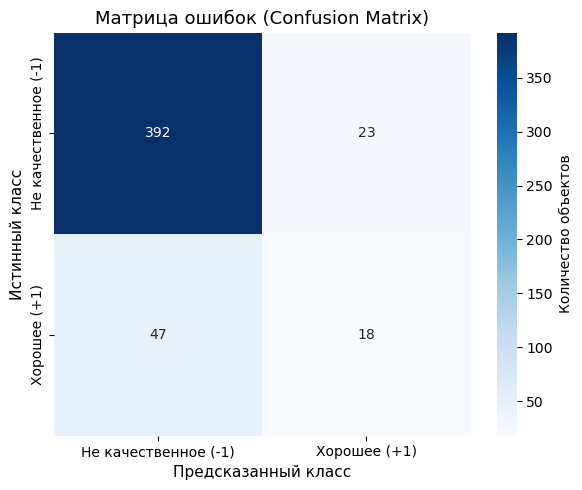

In [6]:
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

csv_filename = "winequality-red.csv"
wine_data = pd.read_csv(csv_filename, sep=";")

print("Информация")
print(f"Размерность: {wine_data.shape[0]} объектов, {wine_data.shape[1]} столбцов")
print(f"Число признаков n = {wine_data.shape[1] - 1}\n")

wine_data["label"] = np.where(wine_data["quality"] >= 7, 1, -1)

print("Распределение классов:")
print(wine_data["label"].value_counts())
print(
    f"Хорошее (+1): {np.sum(wine_data['label'] == 1)} | "
    f"Не качественное (-1): {np.sum(wine_data['label'] == -1)}\n"
)

feature_cols = [c for c in wine_data.columns if c not in ("quality", "label")]
X = wine_data[feature_cols].values.astype(np.float64)
y = wine_data["label"].values.astype(np.int64)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0, stratify=y
)


model = LogisticRegression(random_state=0, max_iter=5000)
model.fit(X_train, y_train)

theta = model.coef_[0]
b = model.intercept_[0]

print("Параметры разделяющей гиперповерхности (theta^T * x + b = 0)")
for name, coef in zip(feature_cols, theta):
    print(f"  {name:25s} = {coef:+.6f}")
print(f"  {'intercept (b)':25s} = {b:+.6f}")

terms = " + ".join(f"({c:+.4f})*{n}" for n, c in zip(feature_cols, theta))
terms = terms.replace("+ -", "- ")

print("\nИтоговое уравнение разделяющей гиперплоскости")
print("Граница принятия решений задается уравнением:")
print(f"  {terms} + ({b:+.4f}) = 0")
print("\nПравило классификации:")
print("  f(x) = sign( theta^T * x + b )")
print("  theta^T * x + b >= 0  ==>  Хорошее вино (+1, quality >= 7)")
print("  theta^T * x + b <  0  ==>  Не качественное вино (-1, quality < 7)\n")

y_pred = model.predict(X_test)

cm = confusion_matrix(y_test, y_pred, labels=[-1, 1])
TN, FP = cm[0, 0], cm[0, 1]
FN, TP = cm[1, 0], cm[1, 1]

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, pos_label=1, zero_division=0)
rec = recall_score(y_test, y_pred, pos_label=1, zero_division=0)
f1 = f1_score(y_test, y_pred, pos_label=1, zero_division=0)
spec = TN / (TN + FP) if (TN + FP) > 0 else 0.0

print("Метрики качества модели на тестовой выборке")
print(f"  Accuracy    = {acc:.4f}")
print(f"  Precision   = {prec:.4f}")
print(f"  Recall      = {rec:.4f}")
print(f"  F1-score    = {f1:.4f}")
print(f"  Specificity = {spec:.4f}\n")

def predict_wine(features, sample_name="Образец"):
    x = np.array(features, dtype=float)
    score = float(theta @ x + b)
    result = "Хорошее" if score >= 0 else "Не качественное"
    print(f"[{sample_name}] theta^T*x + b = {score:+.4f} -> {result}")
    return result

print("Тестирование примеров")
predict_wine(
    [7.4, 0.7, 0.0, 1.9, 0.076, 11.0, 34.0, 0.9978, 3.51, 0.56, 9.4],
    "Вино (качество 5)",
)
predict_wine(
    [7.3, 0.65, 0.0, 1.2, 0.065, 15.0, 21.0, 0.9946, 3.39, 0.47, 10.0],
    "Вино (качество 7)",
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Не качественное (-1)", "Хорошее (+1)"],
    yticklabels=["Не качественное (-1)", "Хорошее (+1)"],
    cbar_kws={"label": "Количество объектов"},
)
plt.title("Матрица ошибок (Confusion Matrix)", fontsize=13)
plt.xlabel("Предсказанный класс", fontsize=11)
plt.ylabel("Истинный класс", fontsize=11)
plt.tight_layout()
plt.show()
